# 04 — Destek Vektör Makineleri (SVM) ile Orman Yangını Duyarlılığı

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

SVM, sınıfları birbirinden ayıran **en geniş marjlı** sınırı arar. RBF çekirdeği
sayesinde doğrusal olmayan ilişkileri de yakalayabilir. Regresyon sürümü SVR, hatası
ε genişliğindeki bir tüpün içinde kalan örnekleri cezalandırmaz; sınıflandırma sürümü
SVC olarak adlandırılır. Marj kavramı mesafeye dayandığı için ölçekleme zorunludur.

**Hesaplama notu.** RBF çekirdekli SVM'nin eğitim süresi örnek sayısının yaklaşık
karesiyle büyür. Bu veri setinin eğitim kümesi birkaç bin noktadan oluştuğu için SVM
**bütün eğitim kümesiyle** eğitilir; alt örneklemeye gerek yoktur. Ceza parametresi
doğrulama kümesiyle **C = 1** olarak seçilmiştir.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR, SVC
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


## 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [2]:
X_tr_s, X_te_s = o.olcekli(X_tr, X_te)
X_alt, yr_alt, yc_alt = o.alt_ornek(X_tr_s, yr_tr, yc_tr)   # sınır eğitim kümesinden büyük: tamamı kullanılır
print(f"SVM eğitim kümesi: {len(X_alt)} nokta (eğitim kümesinin %{len(X_alt) / len(X_tr) * 100:.1f}'i)")
reg_model = SVR(C=1)                        # C = 1 (doğrulama kümesiyle seçildi)
reg_model.fit(X_alt, yr_alt)
y_pred = reg_model.predict(X_te_s)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

SVM eğitim kümesi: 5128 nokta (eğitim kümesinin %100.0'i)


Test kümesi metrikleri
----------------------------------
   MAE: 0.2274
   MSE: 0.1136
  RMSE: 0.3370
    R2: 0.5455
   AUC: 0.9180


In [3]:
o.reg_grafikleri(yr_te, y_pred, "Destek Vektör Makineleri (SVM)", "svm")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\svm_regresyon.png'

## 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [4]:
clf = SVC(C=1, class_weight='balanced', random_state=42)
clf.fit(X_alt, yc_alt)
yp = clf.predict(X_te_s)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.8362
   BalancedAcc: 0.8368
      F1_macro: 0.8362
   F1_weighted: 0.8361

              precision    recall  f1-score   support

  Yangın Yok      0.864     0.806     0.834       653
      Yangın      0.811     0.868     0.839       629

    accuracy                          0.836      1282
   macro avg      0.838     0.837     0.836      1282
weighted avg      0.838     0.836     0.836      1282



## 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [5]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.2274 |   0.4998 |    0.3931 | -0.1657 (iyi)
     MSE |   0.1136 |   0.2499 |    0.1978 | -0.0842 (iyi)
    RMSE |   0.3370 |   0.4999 |    0.4447 | -0.1077 (iyi)
      R2 |   0.5455 |  -0.0000 |    0.2086 | +0.3370 (iyi)
     AUC |   0.9180 |   0.5000 |    0.6982 | +0.2198 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.8362 |   0.5094 |    0.6934 | +0.1427
     BalancedAcc |  0.8368 |   0.5000 |    0.6982 | +0.1386
        F1_macro |  0.8362 |   0.3375 |    0.6748 | +0.1614
     F1_weighted |  0.8361 |   0.3438 |    0.6733 | +0.1628
Tek kural: Yükseklik ≤ 1258.0


In [6]:
o.karmasiklik_grafigi(yc_te, yp, "Destek Vektör Makineleri (SVM)", "svm")

Destek Vektör Makineleri (SVM) — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   526    127
      Yangın |    83    546


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\svm_siniflandirma.png'

## 5. Algoritmaya Özgü Analiz

### C Parametresinin Etkisi

C, marj ihlallerine verilen cezayı denetler. Küçük C → yumuşak marj, daha çok hataya
izin verilir ve model düzleşir; büyük C → eğitim verisine sıkı uyum ve aşırı öğrenme
eğilimi. Etkiyi görmek için C değeri logaritmik olarak tarandı.

Destek vektörü sayısı: {'regresyon': 2813, 'siniflandirma': 2239}


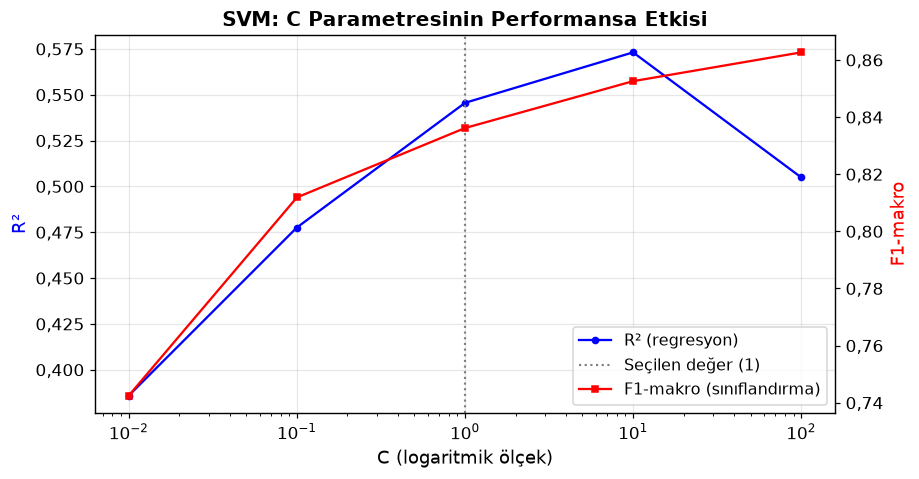

Tarama: [(0.01, 0.3859, 0.7425), (0.1, 0.4775, 0.8119), (1, 0.5455, 0.8362), (10, 0.5731, 0.8526), (100, 0.5049, 0.8626)]
En yüksek R²: 0.5731 (10) · en yüksek F1-makro: 0.8626 (100)


In [7]:
degerler = [0.01, 0.1, 1, 10, 100]
r2_list, f1_list = [], []
for CC in degerler:
    r = SVR(C=CC).fit(X_alt, yr_alt)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te_s))["R2"])
    c = SVC(C=CC, class_weight='balanced', random_state=42).fit(X_alt, yc_alt)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te_s))["F1_macro"])
destek = {"regresyon": int(len(reg_model.support_)), "siniflandirma": int(len(clf.support_))}
print("Destek vektörü sayısı:", destek)
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(1, color="gray", ls=":", lw=1.4, label="Seçilen değer (1)")
ax1.set_xlabel("C (logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("SVM: C Parametresinin Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "svm_c_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [8]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    _olcek = o.StandardScaler().fit(Xa)
    Xa, Xb = _olcek.transform(Xa), _olcek.transform(Xb)
    Xa, yra, ysa = o.alt_ornek(Xa, yra, ysa)
    r_tahmin = SVR(C=1).fit(Xa, yra).predict(Xb)
    c_tahmin = SVC(C=1, class_weight='balanced', random_state=42).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2231 · F1-makro 0.7464


  kat 2: eğitim  4170 · sınama   958 · R² +0.0273 · F1-makro 0.6501


  kat 3: eğitim  4114 · sınama  1014 · R² +0.4490 · F1-makro 0.8173


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4281 · F1-makro 0.8098


  kat 5: eğitim  4150 · sınama   978 · R² +0.5295 · F1-makro 0.8691
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.3314 ± 0.1826
  F1-makro: 0.7785 ± 0.0751


In [9]:
o.sonuc_kaydet("svm", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp], "alt_ornek": int(len(X_alt)), "destek_vektoru": destek})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\svm.json


{'algoritma': 'svm',
 'regresyon': {'MAE': 0.22740348764372742,
  'MSE': 0.11357354131982865,
  'RMSE': 0.33700673779589135,
  'R2': 0.5455465640443153,
  'AUC': 0.9179694062137086},
 'siniflandirma': {'Accuracy': 0.8361934477379095,
  'BalancedAcc': 0.836778765974334,
  'F1_macro': 0.8361535708808343,
  'F1_weighted': 0.8361057186523441},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.22308300758733046,
    0.027272406271487637,
    0.44900815839529296,
    0.4280973691223525,
    0.5294758007816043],
   'F1_macro': [0.7464296690997687,
    0.6500569917865856,
    0.8173109978603991,
    0.809791449426486,
    0.8690856155644888],
   'R2_ort': 0.33138734843161355,
   'R2_std': 0.18256080975045058,
   'F1_ort': 0.7785349447475457,
   'F1_std': 0.07512297715960443},
  'duyarlilik': {'degerler': [0.01, 0.1, 1.0, 10.0, 100.0],
   'R2': [0.3858786054194475,
    0.47754284907251865,
    0.5455465640443153,
    0.5730790981272091,
    0.5048747069319135],
   'F1_macro': [0.74248378425